# Task 3 (Day 3): Train your first honest baselines
**Objective.** Train a model that always guesses the majority, then a logistic regression, and compare both with the benchmark sheet.
**Why it matters.** A baseline tells you how hard the problem is; any fancy model must beat it honestly.
**You will learn.** Training and validation, stratified 5-fold cross-validation, class weights, scores versus yes/no predictions, reading a benchmark table.

In [1]:
import sys, pathlib, inspect, subprocess
ROOT = pathlib.Path.cwd().resolve()
while not (ROOT / 'src').exists(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src')); sys.path.insert(0, str(ROOT / '05_Starter'))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 60); pd.set_option('display.max_colwidth', 110)
from sklearn.model_selection import cross_val_predict
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score, average_precision_score, precision_score, recall_score, f1_score, accuracy_score, confusion_matrix
from cortexhr import config as C, data_loading as D, audit as A, features as F, modeling as M, evaluation as E, reporting as R, runs, workflow as W
import cortexhr_helpers as H; H.DATA = ROOT / '03_Data' / 'csv'      # the OFFICIAL starter helper (unmodified): load, binary_report, risk_bands, catch_rate, group_gap, psi
print('Python', sys.version.split()[0], '| project root:', ROOT)

Python 3.12.3 | project root: /home/claude/cortexhr_phase1


In [2]:
mk = lambda est, monthly=False: Pipeline([('features', F.build_pipeline(monthly)), ('model', est)])
LRB = lambda **kw: LogisticRegression(class_weight='balanced', max_iter=2000, random_state=C.SEED, **kw)
def metrics_row(y, s, thr=0.5):
    r = E.binary_report(y, s, threshold=thr); return {k: r[k] for k in ['roc_auc', 'pr_auc', 'precision', 'recall', 'f1', 'accuracy', 'top_precision', 'top_recall']}

---
# Stage 1 of 12: Data Collection
Load the data and the benchmark sheet.

In [3]:
S = runs.load_model_frame(True); Xtr, ytr, Xte, yte, folds, df = S['Xtr'], S['ytr'], S['Xte'], S['yte'], S['folds'], S['df']
bench = H.load('baseline_benchmarks'); bench

                                               model  roc_auc_mean  roc_auc_sd  pr_auc_mean  precision_mean  recall_mean  f1_mean  accuracy_mean  \
0                               Dummy (always stays)         0.500       0.000        0.146           0.000        0.000    0.000          0.854   
1        Logistic Regression (class_weight=balanced)         0.713       0.010        0.332           0.260        0.630    0.368          0.683   
2                  Decision Tree (depth 4, balanced)         0.650       0.019        0.256           0.234        0.524    0.322          0.676   
3                Random Forest (300 trees, balanced)         0.715       0.018        0.336           0.523        0.089    0.151          0.854   
4  LEAKY Logistic Regression (adds exit information)         1.000       0.000        1.000           1.000        1.000    1.000          1.000   

                                                              comment  
0  Looks 85% accurate yet catches nobod

---
# Stage 2 of 12: Data Understanding
What is being predicted and what does the benchmark table mean?

Target `left_within_12m` (1 = left within 12 months). Each benchmark row is a model with cross-validated ROC-AUC, PR-AUC, precision, recall, F1 and accuracy: the number to beat or understand. The leaky row (ROC-AUC ~1.0) is the cautionary tale.

In [4]:
print('rows', len(df), '| leavers', int(S['y'].sum()), f'({100 * S["y"].mean():.2f}%) | inputs', S['X'].shape[1], '| join report:', S['join_report']['attendance_matched_rows'], 'rows with monthly history')

rows 2383 | leavers 349 (14.65%) | inputs 43 | join report: 383 rows with monthly history


---
# Stage 3 of 12: Data Quality Audit
Re-check that nothing unsafe reaches the models.

In [5]:
F.assert_safe_input_columns(S['X'].columns); print('safety guard passed: no target, id, date, leakage or metadata columns in X')
print('max single-column AUC among inputs:', A.single_column_power(df, [c for c in S['X'].columns if c in df.columns]).single_column_auc.max().round(3), '(< 0.9 = no hidden leak)')

safety guard passed: no target, id, date, leakage or metadata columns in X
max single-column AUC among inputs: 0.6 (< 0.9 = no hidden leak)


---
# Stage 4 of 12: Exploratory Data Analysis (EDA)
Class balance and a first look at what separates leavers.

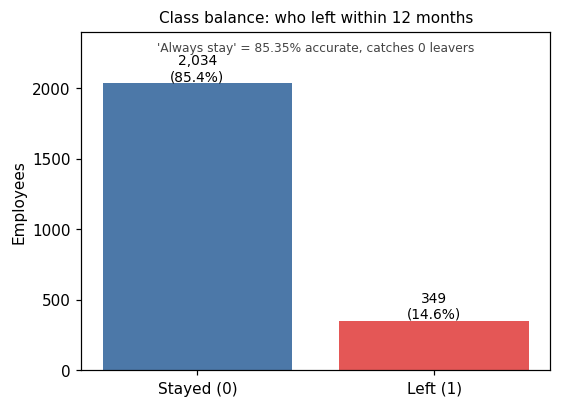

In [6]:
A.plot_class_balance(A.class_balance(df));

In [7]:
W.numeric_vs_target(df, [c for c in C.NUMERIC_CORE if c in df.columns]).head(10)

left_within_12m                  mean_stayed  mean_left  relative_diff_pct
manager_changes_12m                    0.284      0.470               65.7
avg_overtime_hours_per_month_3m        2.002      3.144               57.0
months_since_last_raise               10.498     13.948               32.9
commute_distance_km                   12.070     14.424               19.5
wfh_share_3m                           0.388      0.324              -16.5
internal_transfers                     0.085      0.072              -15.3
tenure_months                         38.429     33.814              -12.0
raises_received                        2.343      2.074              -11.4
last_engagement_score                  3.494      3.136              -10.3
months_since_last_promotion           26.559     24.219               -8.8

---
# Stage 5 of 12: Data Cleaning
Cleaning is applied inside the pipeline so it is repeated safely in every fold.

In [8]:
print(S['join_report'])
print(inspect.getsource(F.RawCleaner))

{'rows_before_join': 2383, 'rows_after_join': 2383, 'cardinality': 'attrition(1) -> aggregates(1), validated one_to_one', 'attendance_matched_rows': 383, 'payroll_matched_rows': 383, 'unmatched_rows_attendance': 2000, 'unmatched_rows_payroll': 2000, 'rows_dropped': 0, 'window_months': 3, 'temporal_cutoff': 'only complete months with month_end <= observation_date; last `window` such months', 'payroll_exact_duplicates_removed': 15, 'rows_before': 2389, 'exact_duplicates_dropped': 6, 'rows_after': 2383}
class RawCleaner(BaseEstimator, TransformerMixin):
    """Stateless fixes: canonical city, impossible values -> NaN, rates clipped to [0, 1]. No learned statistics.
    Missing INPUT columns are added as NaN (and imputed later) so scoring never crashes on an incomplete record."""
    def __init__(self, expected=None):
        self.expected = expected
    def fit(self, X, y=None): return self
    def transform(self, X):
        d = pd.DataFrame(X).copy()
        for c in (self.expected or [

---
# Stage 6 of 12: Feature Engineering
The pipeline from Task 2 turns raw rows into model-ready numbers.

In [9]:
pipe = F.build_pipeline(True).fit(Xtr, ytr); Zt = pipe.transform(Xtr)
print('raw inputs', Xtr.shape[1], '-> model-ready columns', Zt.shape[1]); list(Zt.columns)[:12]

raw inputs 43 -> model-ready columns 142


['job_level', 'tenure_months', 'total_experience_years', 'previous_employers_count', 'commute_distance_km', 'comp_ratio', 'raises_received', 'last_raise_pct', 'months_since_last_raise', 'promotions_received', 'months_since_last_promotion', 'internal_transfers']

---
# Stage 7 of 12: Train-Test Split
Define X and y, stratified 80/20 split, 5 stratified folds with a fixed random state.

In [10]:
from sklearn.model_selection import StratifiedKFold
print('train', Xtr.shape, 'test', Xte.shape, '| leaver rate train/test:', round(ytr.mean(), 4), round(yte.mean(), 4), '(stratified)')
folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=C.SEED).split(Xtr, ytr))
print('fold sizes (train, validation):', [(len(a), len(b)) for a, b in folds]); print('the test rows are NOT touched until Task 4')

train (1906, 43) test (477, 43) | leaver rate train/test: 0.1464 0.1468 (stratified)
fold sizes (train, validation): [(1524, 382), (1525, 381), (1525, 381), (1525, 381), (1525, 381)]
the test rows are NOT touched until Task 4


---
# Stage 8 of 12: Model Building
Train DummyClassifier, then LogisticRegression(class_weight='balanced'); add a tree and a forest. Same folds for all.

In [11]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
models = {'Dummy (always stays)': mk(DummyClassifier(strategy='most_frequent'), True), 'Logistic Regression (balanced)': mk(LRB(), True),
          'Decision Tree (depth 4, balanced)': mk(DecisionTreeClassifier(max_depth=4, class_weight='balanced', random_state=C.SEED), True),
          'Random Forest (300, balanced)': mk(RandomForestClassifier(n_estimators=300, class_weight='balanced', min_samples_leaf=3, random_state=C.SEED), True)}
oof = {n: cross_val_predict(m, Xtr, ytr, cv=folds, method='predict_proba')[:, 1] for n, m in models.items()}   # probability for EVERY row, out-of-fold
pd.DataFrame(oof).describe().T[['mean', 'min', 'max']].round(3)

                                    mean    min    max
Dummy (always stays)               0.000  0.000  0.000
Logistic Regression (balanced)     0.380  0.000  0.992
Decision Tree (depth 4, balanced)  0.427  0.000  1.000
Random Forest (300, balanced)      0.228  0.027  0.693

---
# Stage 9 of 12: Model Evaluation
Metrics per fold, confusion matrices, benchmark comparison, leakage alarm.

In [12]:
rows = []
for name, s in oof.items():
    fm = []
    for _, te in folds:
        yt, st_ = ytr.iloc[te].to_numpy(), s[te]; pr = (st_ >= 0.5).astype(int)
        fm.append(dict(roc_auc=roc_auc_score(yt, st_), pr_auc=average_precision_score(yt, st_), precision=precision_score(yt, pr, zero_division=0),
                       recall=recall_score(yt, pr, zero_division=0), f1=f1_score(yt, pr, zero_division=0), accuracy=accuracy_score(yt, pr), undefined_precision=int(pr.sum() == 0)))
    f = pd.DataFrame(fm); rows.append({'model': name, **f.mean().round(3).to_dict(), 'roc_auc_sd': round(f.roc_auc.std(), 3)})
results = pd.DataFrame(rows).set_index('model'); results

                                   roc_auc  pr_auc  precision  recall     f1  accuracy  undefined_precision  roc_auc_sd
model                                                                                                                  
Dummy (always stays)                 0.500   0.146      0.000   0.000  0.000     0.854                  1.0       0.000
Logistic Regression (balanced)       0.709   0.325      0.262   0.584  0.361     0.696                  0.0       0.021
Decision Tree (depth 4, balanced)    0.629   0.235      0.216   0.534  0.305     0.639                  0.0       0.037
Random Forest (300, balanced)        0.700   0.316      0.474   0.093  0.155     0.850                  0.0       0.025

**Undefined precision.** When a model predicts nobody will leave (the Dummy), precision = 0/0 is undefined; `zero_division=0` reports it as 0 and `undefined_precision` counts those folds. Accuracy is shown only as a supplement.

In [13]:
print('OFFICIAL cortexhr_helpers.binary_report for every model (top 10% = int(n x 0.10) highest scores):')
pd.DataFrame({n: H.binary_report(ytr, sc) for n, sc in oof.items()}).T.round(3)

OFFICIAL cortexhr_helpers.binary_report for every model (top 10% = int(n x 0.10) highest scores):


                                   roc_auc  pr_auc  precision_at_top  recall_at_top  f1_at_top  base_rate
Dummy (always stays)                 0.500   0.146             0.147          0.100      0.119      0.146
Logistic Regression (balanced)       0.710   0.314             0.374          0.254      0.303      0.146
Decision Tree (depth 4, balanced)    0.621   0.230             0.332          0.226      0.269      0.146
Random Forest (300, balanced)        0.699   0.287             0.368          0.251      0.299      0.146

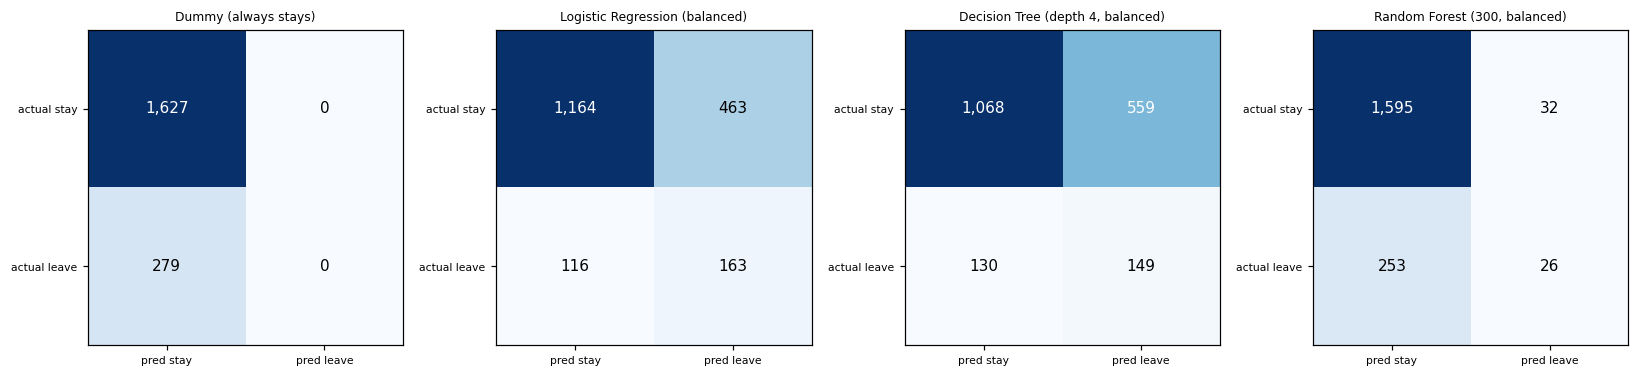

In [14]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, (nm, s) in zip(axes, oof.items()):
    tn, fp, fn, tp = confusion_matrix(ytr, (s >= 0.5).astype(int), labels=[0, 1]).ravel(); cm = np.array([[tn, fp], [fn, tp]]); ax.imshow(cm, cmap='Blues')
    for i in range(2):
        for j in range(2): ax.text(j, i, f'{cm[i, j]:,}', ha='center', va='center', color='white' if cm[i, j] > cm.max() / 2 else 'black')
    ax.set_xticks([0, 1], ['pred stay', 'pred leave'], fontsize=7); ax.set_yticks([0, 1], ['actual stay', 'actual leave'], fontsize=7); ax.set_title(nm, fontsize=8)
fig.tight_layout();

In [15]:
bmap = {'Dummy (always stays)': 'Dummy (always stays)', 'Logistic Regression (balanced)': 'Logistic Regression (class_weight=balanced)',
        'Decision Tree (depth 4, balanced)': 'Decision Tree (depth 4, balanced)', 'Random Forest (300, balanced)': 'Random Forest (300 trees, balanced)'}
bi = bench.set_index('model')
cmp_ = pd.DataFrame({'my_roc_auc': results.roc_auc, 'benchmark_roc_auc': [bi.loc[bmap[m], 'roc_auc_mean'] for m in results.index],
                     'my_recall': results.recall, 'benchmark_recall': [bi.loc[bmap[m], 'recall_mean'] for m in results.index],
                     'my_precision': results.precision, 'benchmark_precision': [bi.loc[bmap[m], 'precision_mean'] for m in results.index]})
cmp_['delta_roc_auc'] = cmp_.my_roc_auc - cmp_.benchmark_roc_auc; cmp_.round(3)

                                   my_roc_auc  benchmark_roc_auc  my_recall  benchmark_recall  my_precision  benchmark_precision  delta_roc_auc
model                                                                                                                                          
Dummy (always stays)                    0.500              0.500      0.000             0.000         0.000                0.000          0.000
Logistic Regression (balanced)          0.709              0.713      0.584             0.630         0.262                0.260         -0.004
Decision Tree (depth 4, balanced)       0.629              0.650      0.534             0.524         0.216                0.234         -0.021
Random Forest (300, balanced)           0.700              0.715      0.093             0.089         0.474                0.523         -0.015

In [16]:
Zl = pd.DataFrame({'exit_date_filled': df.loc[Xtr.index, 'exit_date'].notna().astype(int).to_numpy(), 'fnf_filled': df.loc[Xtr.index, 'fnf_settlement_amount'].notna().astype(int).to_numpy()})
pl = cross_val_predict(LogisticRegression(max_iter=500), Zl, ytr.to_numpy(), cv=folds, method='predict_proba')[:, 1]
print('LEAKY demo ROC-AUC =', round(roc_auc_score(ytr, pl), 3), '-> above 0.9 sends you back to find leakage')
print('best honest model ROC-AUC =', round(results.roc_auc.max(), 3), '| any honest model above 0.9?', bool((results.roc_auc > 0.9).any()))

LEAKY demo ROC-AUC = 1.0 -> above 0.9 sends you back to find leakage
best honest model ROC-AUC = 0.709 | any honest model above 0.9? False


### Five sentences: where am I above/below the benchmark, and is the gap believable?

In [17]:
lr, d_, dt_, rf_ = results.loc['Logistic Regression (balanced)'], results.loc['Dummy (always stays)'], results.loc['Decision Tree (depth 4, balanced)'], results.loc['Random Forest (300, balanced)']
b = bi.loc['Logistic Regression (class_weight=balanced)']
s5 = [f'1. My logistic regression scores ROC-AUC {lr.roc_auc:.3f} (+/-{lr.roc_auc_sd:.3f}) against the benchmark {b.roc_auc_mean:.3f}: {abs(lr.roc_auc - b.roc_auc_mean):.3f} {"below" if lr.roc_auc < b.roc_auc_mean else "above"}, a believable gap because I cross-validate on 80% of the rows and the fold-to-fold spread is itself about {lr.roc_auc_sd:.2f}.',
      f'2. The always-stay Dummy has accuracy {d_.accuracy:.3f} but ROC-AUC 0.500 and recall 0, so it looks good and finds no leaver.',
      f'3. The balanced logistic regression finds {lr.recall:.0%} of leavers at precision {lr.precision:.0%}, so most flagged people are false alarms: the price of catching more leavers when only 14.6% leave.',
      f'4. The depth-4 tree ({dt_.roc_auc:.3f}) is weaker than the logistic regression, and the forest ({rf_.roc_auc:.3f}) ranks about as well but almost never says leave at 0.5 (recall {rf_.recall:.0%}).',
      f'5. No honest model passes 0.90 (best {results.roc_auc.max():.3f}), so there is no sign of leakage, whereas the deliberately leaky demo reaches {roc_auc_score(ytr, pl):.2f}.']
print(*s5, sep='\n')

1. My logistic regression scores ROC-AUC 0.709 (+/-0.021) against the benchmark 0.713: 0.004 below, a believable gap because I cross-validate on 80% of the rows and the fold-to-fold spread is itself about 0.02.
2. The always-stay Dummy has accuracy 0.854 but ROC-AUC 0.500 and recall 0, so it looks good and finds no leaver.
3. The balanced logistic regression finds 58% of leavers at precision 26%, so most flagged people are false alarms: the price of catching more leavers when only 14.6% leave.
4. The depth-4 tree (0.629) is weaker than the logistic regression, and the forest (0.700) ranks about as well but almost never says leave at 0.5 (recall 9%).
5. No honest model passes 0.90 (best 0.709), so there is no sign of leakage, whereas the deliberately leaky demo reaches 1.00.


### Think for yourself: why does a decision tree look excellent on its training data but weaker in cross-validation?

In [18]:
tree = mk(DecisionTreeClassifier(random_state=C.SEED), True)
train_auc = roc_auc_score(ytr, tree.fit(Xtr, ytr).predict_proba(Xtr)[:, 1])
cv_auc = roc_auc_score(ytr, cross_val_predict(tree, Xtr, ytr, cv=folds, method='predict_proba')[:, 1])
print(f'unlimited tree: in-sample ROC-AUC = {train_auc:.3f}   out-of-fold ROC-AUC = {cv_auc:.3f}')

unlimited tree: in-sample ROC-AUC = 1.000   out-of-fold ROC-AUC = 0.542


**Answer.** An unlimited tree keeps splitting until it has memorised every training row, noise included, so it scores ~1.0 on rows it has seen. On unseen rows the memorised noise does not repeat, so the score falls to ~0.55. Only the cross-validated number is a fair estimate.

### Extra: class weights versus SMOTE (synthetic minority oversampling, training folds only)

In [19]:
smote_oof = M.oof_scores_smote(Xtr, ytr, folds, True)
plain_oof = cross_val_predict(mk(LogisticRegression(max_iter=2000, random_state=C.SEED), True), Xtr, ytr, cv=folds, method='predict_proba')[:, 1]
lr_scores = oof['Logistic Regression (balanced)']
pd.DataFrame({'LR balanced weights': [roc_auc_score(ytr, lr_scores), average_precision_score(ytr, lr_scores)], 'LR no weights': [roc_auc_score(ytr, plain_oof), average_precision_score(ytr, plain_oof)],
              'LR + SMOTE': [roc_auc_score(ytr, smote_oof), average_precision_score(ytr, smote_oof)]}, index=['ROC-AUC', 'PR-AUC']).round(3)

         LR balanced weights  LR no weights  LR + SMOTE
ROC-AUC                0.710          0.713       0.698
PR-AUC                 0.314          0.324       0.302

SMOTE only touches training folds (validation rows keep the real 14.6% mix) and gives no ranking gain over class weights here. The in-house `SimpleSMOTE` is in `modeling.py`; imbalanced-learn can replace it.

---
# Stage 10 of 12: Hyperparameter Tuning
Tune on the training folds only. The headline baseline above stays the documented default configuration.

In [20]:
g1 = {f'LR C={c}': {'C_': c} for c in [0.01, 0.03, 0.1, 0.3, 1, 3]}
t_lr = W.tune_grid(lambda C_: mk(LRB(C=C_), True), g1, Xtr, ytr, folds)
g2 = {f'Tree depth={d}': {'d': d} for d in [2, 3, 4, 5, 6, 8]}
t_tree = W.tune_grid(lambda d: mk(DecisionTreeClassifier(max_depth=d, class_weight='balanced', random_state=C.SEED), True), g2, Xtr, ytr, folds)
pd.concat([t_lr, t_tree]).sort_values('cv_roc_auc', ascending=False).round(4).reset_index(drop=True)

         setting  cv_roc_auc  cv_roc_auc_sd  cv_pr_auc
0       LR C=0.1      0.7140         0.0283     0.3291
1      LR C=0.03      0.7136         0.0357     0.3314
2       LR C=0.3      0.7133         0.0234     0.3222
3      LR C=0.01      0.7117         0.0401     0.3261
4         LR C=1      0.7095         0.0209     0.3138
5         LR C=3      0.7059         0.0215     0.3077
6   Tree depth=2      0.6387         0.0453     0.2175
7   Tree depth=4      0.6285         0.0366     0.2298
8   Tree depth=3      0.6267         0.0685     0.2227
9   Tree depth=5      0.5992         0.0420     0.2185
10  Tree depth=6      0.5874         0.0181     0.1988
11  Tree depth=8      0.5519         0.0277     0.1721

Tuning moves ROC-AUC by less than the fold-to-fold spread, so tuned and default models are effectively the same: the limit is the data, not the settings.

---
# Stage 11 of 12: Model Interpretation
Which inputs drive the logistic regression?

In [21]:
tr, va = folds[0]; m = mk(LRB(), True).fit(Xtr.iloc[tr], ytr.iloc[tr])
W.logreg_coefficients(m, 12)

                               feature  coefficient
0                         role_id_R012    -1.620521
1            raise_recency_bucket_18m+     1.579473
2                         role_id_R035    -1.577491
3   highest_education_M.A. Social Work    -1.496902
4                         role_id_R015    -1.390232
5                 highest_education_CA     1.379928
6              work_location_Delhi NCR    -1.356931
7                         role_id_R018     1.315478
8                         role_id_R046     1.170009
9                 work_location_Mumbai     0.998322
10          raise_recency_bucket_6-12m    -0.950558
11                        role_id_R008    -0.941772

In [22]:
W.permutation_table(m, Xtr.iloc[va], ytr.iloc[va], n_repeats=3, top=10)   # validation rows only

                    column  auc_drop        sd
0            tenure_months  0.070753  0.021252
1         annual_fixed_pay  0.067740  0.017852
2                  role_id  0.060638  0.004934
3                job_level  0.059597  0.010210
4            department_id  0.054612  0.013209
5  months_since_last_raise  0.043273  0.014381
6    last_engagement_score  0.040042  0.011937
7           last_raise_pct  0.016506  0.001477
8      manager_changes_12m  0.014479  0.003551
9  last_performance_rating  0.012507  0.003383

---
# Stage 12 of 12: Final Conclusions and Recommendations
Conclusions and recommendations.

In [23]:
print(f'''RESULT: balanced LR ROC-AUC {lr.roc_auc:.3f} vs benchmark {b.roc_auc_mean:.3f}; Dummy accuracy {d_.accuracy:.3f} but recall 0; tree/forest do not beat it; no score above 0.90, no leakage.
TRADE-OFF: recall {lr.recall:.0%} with precision {lr.precision:.0%}: finds more leavers, creates many false alarms. Fine for a ranked human review list, unsafe for automatic action.
RECOMMENDATIONS: 1) keep logistic regression as the transparent baseline to beat; 2) any new model must beat it on the SAME folds; 3) report PR-AUC/recall not accuracy; 4) investigate any future score above 0.90 for leakage first.''')

RESULT: balanced LR ROC-AUC 0.709 vs benchmark 0.713; Dummy accuracy 0.854 but recall 0; tree/forest do not beat it; no score above 0.90, no leakage.
TRADE-OFF: recall 58% with precision 26%: finds more leavers, creates many false alarms. Fine for a ranked human review list, unsafe for automatic action.
RECOMMENDATIONS: 1) keep logistic regression as the transparent baseline to beat; 2) any new model must beat it on the SAME folds; 3) report PR-AUC/recall not accuracy; 4) investigate any future score above 0.90 for leakage first.


### Completion checklist (checked by code)

In [24]:
checks = {
    "'Logistic regression is near the benchmark (about 0.71 ROC-AUC)'": abs(lr.roc_auc - 0.713) < 0.05,
    "'I can explain the Dummy result (accuracy high, ROC-AUC 0.5, recall 0)'": d_.roc_auc == 0.5 and d_.recall == 0,
    "'A score above 0.9 would send me back to find leakage (none found)'": not (results.roc_auc > 0.9).any(),
    "'Same folds used for every model'": len(folds) == 5,
    "'Split is stratified and reproducible'": abs(ytr.mean() - yte.mean()) < 0.01
}
status = {k: ('MANUAL' if isinstance(v, str) and v == 'MANUAL' else 'PASS' if bool(v) else 'FAIL') for k, v in checks.items()}
for k, v in status.items(): print(f'[{v}]', k)
assert 'FAIL' not in status.values()

[PASS] 'Logistic regression is near the benchmark (about 0.71 ROC-AUC)'
[PASS] 'I can explain the Dummy result (accuracy high, ROC-AUC 0.5, recall 0)'
[PASS] 'A score above 0.9 would send me back to find leakage (none found)'
[PASS] 'Same folds used for every model'
[PASS] 'Split is stratified and reproducible'


### Evidence for your report
Comparison table and 5-sentence note above (also `reports/baseline_model_comparison.md`).
References: [scikit-learn](https://github.com/scikit-learn/scikit-learn) | [pandas](https://github.com/pandas-dev/pandas) | [imbalanced-learn](https://github.com/scikit-learn-contrib/imbalanced-learn)
**How real companies do it:** if a new model scores far above the benchmark, experienced teams get suspicious before they celebrate.
**Connects to Task 4:** scores exist but are not yet judged properly; next we set the right metrics and risk bands.
**You can now say:** *I trained and honestly compared baseline models.*